# OPTIONAL Workbook for Final Project, Part 3

Your group is welcome to work on a local version of a notebook for this assignment.

This workspace is here if you'd rather not have to install all necessary packages locally.

You can download any json files to your local computer to add them to your local jekyll page.

To download, you can right-click on the file and hit download.  For example, with the following code:

```python
from vega_datasets import data
import altair as alt

source = data.cars()
source.rename(columns={"Miles_per_Gallon":"Miles per Gallon"}, 
              inplace=True)


chart = alt.Chart(source).mark_circle(size=60).encode(
    x='Horsepower',
    y='Miles per Gallon',
    color='Origin',
    tooltip=['Name', 'Origin', 'Horsepower', 'Miles per Gallon']
).interactive()

chart.properties(width='container').save("cars.json")
```

You can download from the side bar like this:

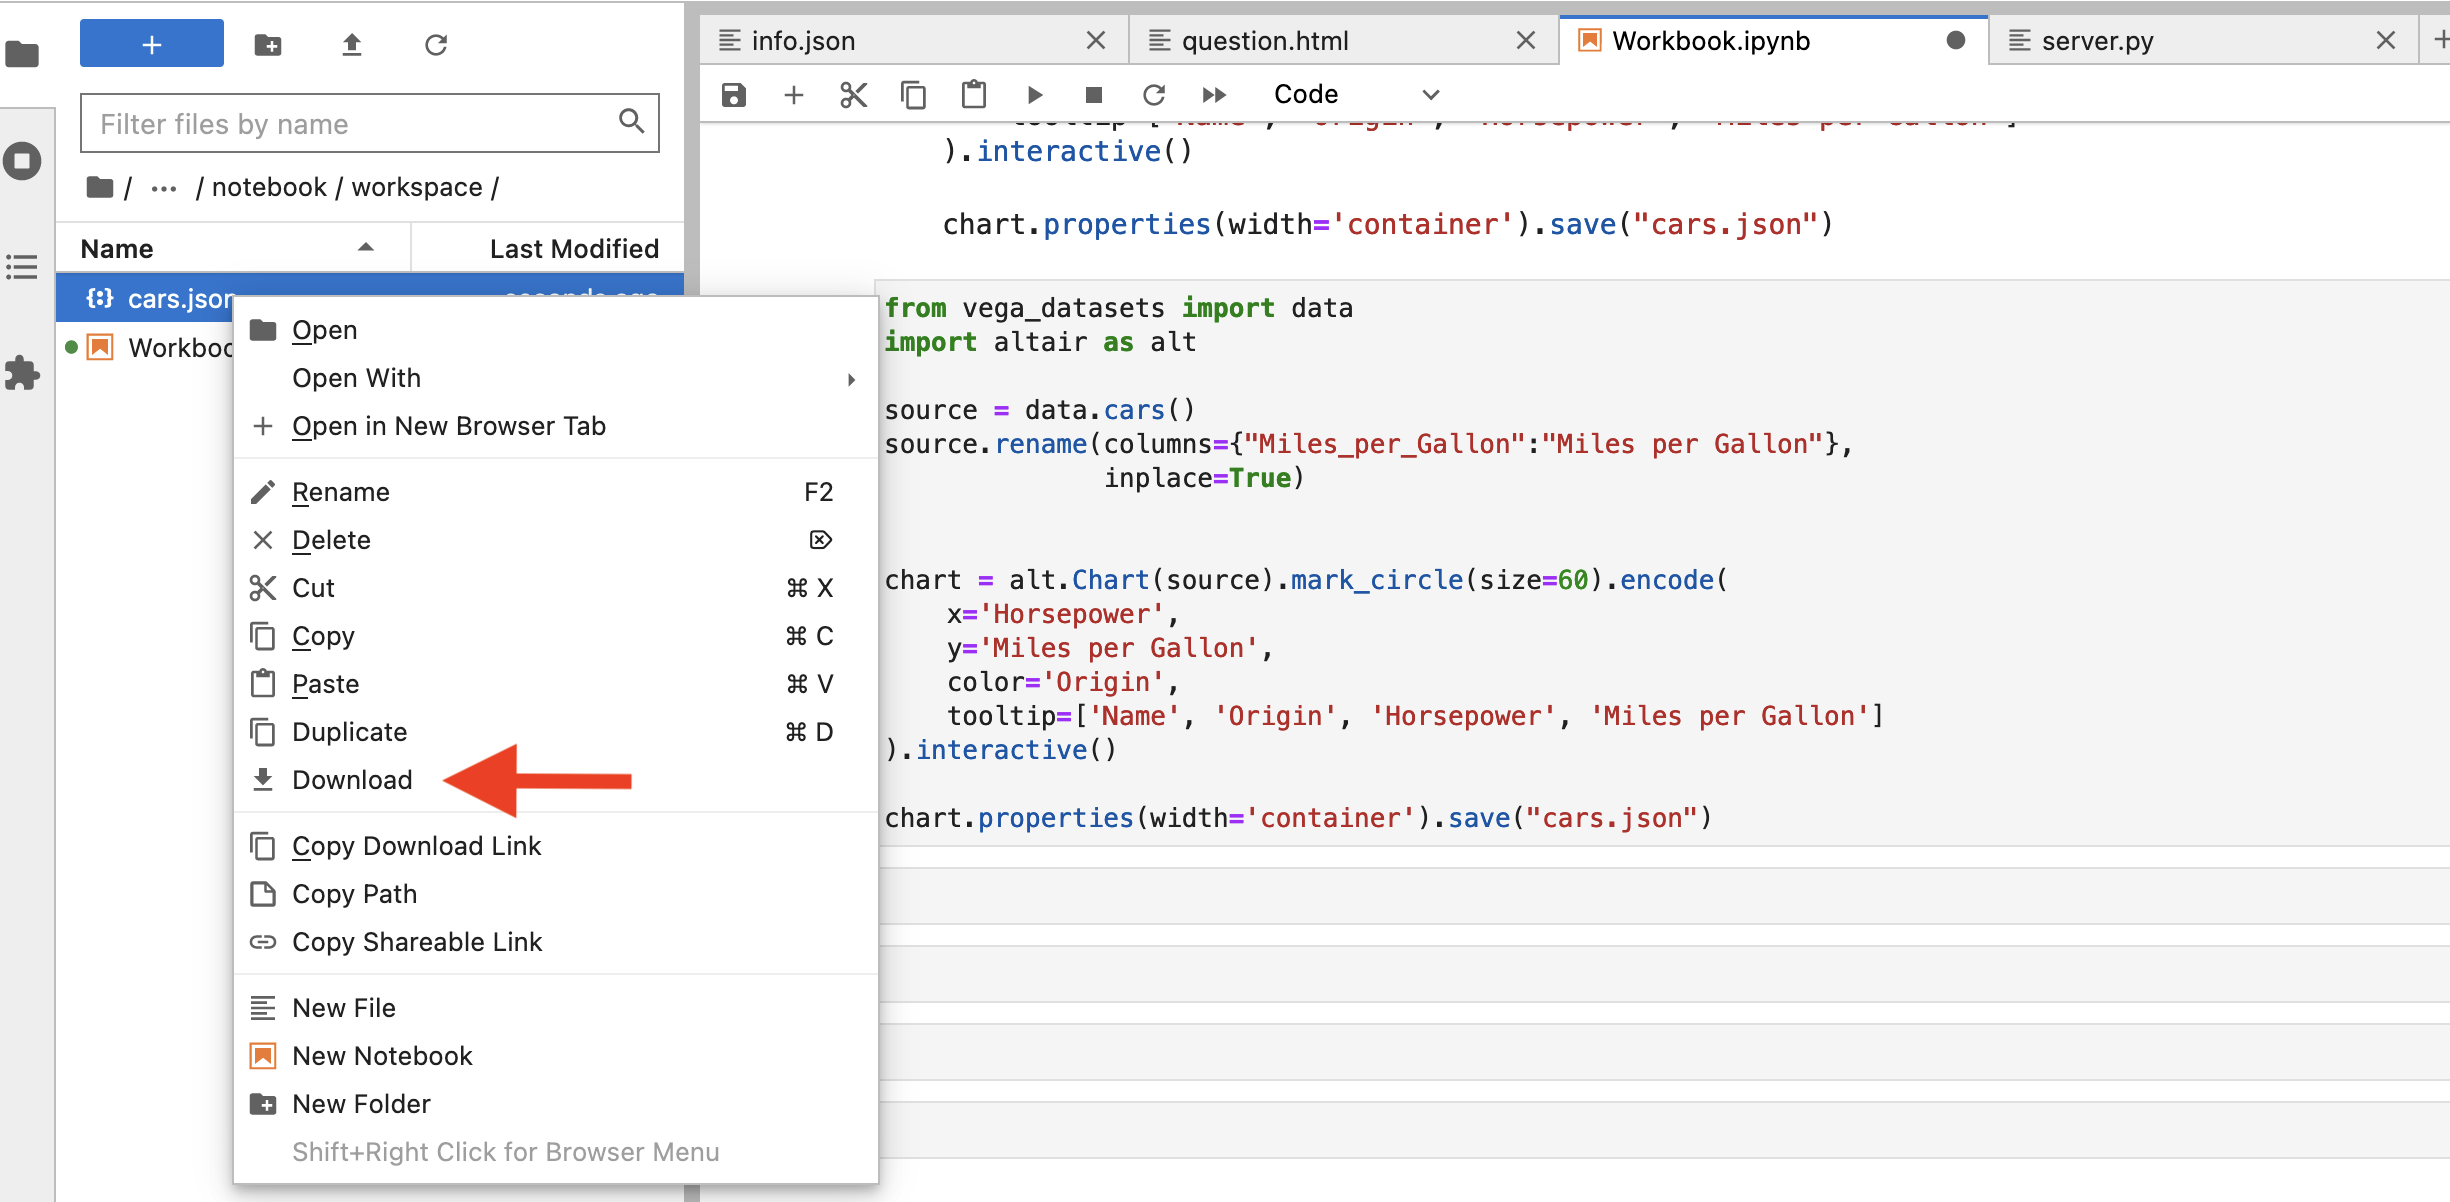

Group 32, Colton Murphy

In [1]:
import pandas as pd
import altair as alt

In [2]:
scorecard = pd.read_csv('Most-Recent-Cohorts-Institution.csv', na_values = 'PS',low_memory=False)
scorecard.head()

,UNITID,OPEID,OPEID6,INSTNM,CITY,STABBR,ZIP,ACCREDAGENCY,INSTURL,NPCURL,...,GT_THRESHOLD_INC1_P10,GT_THRESHOLD_INC2_P10,GT_THRESHOLD_INC3_P10,COUNT_NWNE_INC1_P10,COUNT_NWNE_INC2_P10,COUNT_NWNE_INC3_P10,IN_STATE_P10,IN_STATE_INC1_P10,IN_STATE_INC2_P10,IN_STATE_INC3_P10
0,100654,100200.0,1002.0,Alabama A & M University,Normal,AL,35762,Southern Association of Colleges and Schools C...,www.aamu.edu/,www.aamu.edu/admissions-aid/tuition-fees/net-p...,...,0.5691,0.6909,0.6714,110.0,38.0,11.0,929.0,647.0,208.0,71.0
1,100663,105200.0,1052.0,University of Alabama at Birmingham,Birmingham,AL,35294-0110,Southern Association of Colleges and Schools C...,https://www.uab.edu/,https://tcc.ruffalonl.com/University of Alabam...,...,0.7464,0.8217,0.8495,178.0,84.0,58.0,2802.0,1299.0,834.0,667.0
2,100690,2503400.0,25034.0,Amridge University,Montgomery,AL,36117-3553,Southern Association of Colleges and Schools C...,https://www.amridgeuniversity.edu/,https://www2.amridgeuniversity.edu:9091/,...,NaN,NaN,NaN,NaN,NaN,NaN,158.0,NaN,NaN,NaN
3,100706,105500.0,1055.0,University of Alabama in Huntsville,Huntsville,AL,35899,Southern Association of Colleges and Schools C...,www.uah.edu/,uah.clearcostcalculator.com/student/default/ne...,...,0.7946,0.8714,0.8468,91.0,40.0,26.0,1271.0,584.0,351.0,335.0
4,100724,100500.0,1005.0,Alabama State University,Montgomery,AL,36104-0271,Southern Association of Colleges and Schools C...,www.alasu.edu/,tcc.ruffalonl.com/Alabama State University/Fre...,...,0.5696,0.6627,0.7073,163.0,45.0,5.0,1343.0,989.0,289.0,69.0


In [3]:
bachelors = scorecard.loc[scorecard['PREDDEG'] ==3]
bachelors.shape

(1946, 3379)

In [4]:
dash_columns = ['INSTNM', 'CITY', 'STABBR', 'CONTROL', 'UGDS', 'COSTT4_A', 'C150_4', 'GRAD_DEBT_MDN','GRAD_DEBT_MDN10YR','MD_EARN_WNE_P6', 'MD_EARN_WNE_P8', 'MD_EARN_WNE_P10']
dash = bachelors[dash_columns].dropna(subset=['COSTT4_A','MD_EARN_WNE_P10']).copy()
dash.shape

(1682, 12)

In [5]:
dash['School Type'] = dash['CONTROL'].map({1:"Public", 2: "Private Non-Profit", 3: 'Private For-Profit'})

dash = dash.rename(columns = {'INSTNM' : 'School', 'CITY' : 'City', 'STABBR' : 'State', 'UGDS' : 'Undergrads', 'COSTT4_A' : 'Cost Per Year', 'C150_4' : 'Grad Rate 6YR', 'GRAD_DEBT_MDN' : 'Median Debt Amount', 'MD_EARN_WNE_P6' : 'Year_6_Earnings', 'MD_EARN_WNE_P8' : 'Year_8_Earnings', 'MD_EARN_WNE_P10' :'Year_10_Earnings', 'GRAD_DEBT_MDN10YR' : 'Monthly Loan Payment'}) 

dash.head()

,School,City,State,CONTROL,Undergrads,Cost Per Year,Grad Rate 6YR,Median Debt Amount,Monthly Loan Payment,Year_6_Earnings,Year_8_Earnings,Year_10_Earnings,School Type
0,Alabama A & M University,Normal,AL,1,6124.0,27732.0,0.2771,27204.0,309.172820,35382.0,39460.0,41266.0,Public
1,University of Alabama at Birmingham,Birmingham,AL,1,11635.0,27987.0,0.6612,21250.0,241.505750,49680.0,55784.0,59631.0,Public
3,University of Alabama in Huntsville,Huntsville,AL,1,6591.0,32089.0,0.6246,20550.0,233.550267,58567.0,67658.0,72098.0,Public
4,Alabama State University,Montgomery,AL,1,3477.0,23655.0,0.3070,28197.0,320.458242,32390.0,37738.0,40585.0,Public
5,The University of Alabama,Tuscaloosa,AL,1,33227.0,33924.0,0.7366,21500.0,244.346994,59485.0,64384.0,66081.0,Public


In [15]:
dash[['Cost Per Year', 'Year_10_Earnings', 'Median Debt Amount']].corr()

,Cost Per Year,Year_10_Earnings,Median Debt Amount
Cost Per Year,1.000000,0.522120,0.209853
Year_10_Earnings,0.522120,1.000000,-0.093463
Median Debt Amount,0.209853,-0.093463,1.000000


In [19]:
dash['Earnings per Cost Dollar'] = dash['Year_10_Earnings']/ dash['Cost Per Year']
dash.sort_values('Earnings per Cost Dollar', ascending=False)[['School', 'State', 'School Type', 'Cost Per Year', 'Year_10_Earnings']].head(10)

,School,State,School Type,Cost Per Year,Year_10_Earnings
2158,United States Merchant Marine Academy,NY,Public,6923.0,103283.0
1973,CUNY Bernard M Baruch College,NY,Public,12312.0,83742.0
4381,Bais Medrash Toras Chesed,NJ,Private Non-Profit,14000.0,84562.0
1979,CUNY Graduate School and University Center,NY,Public,11928.0,69504.0
1981,CUNY Hunter College,NY,Public,12400.0,70502.0
2438,Ohio University-Eastern Campus,OH,Public,11075.0,61938.0
1978,CUNY City College,NY,Public,12926.0,69594.0
1976,CUNY Brooklyn College,NY,Public,12517.0,66519.0
1988,CUNY Queens College,NY,Public,12914.0,68324.0
1982,CUNY John Jay College of Criminal Justice,NY,Public,12497.0,65870.0


In [23]:
dash['Growth 6 to 10'] = dash['Year_10_Earnings'] - dash['Year_6_Earnings']
dash.groupby('School Type')['Growth 6 to 10'].median()

School Type
Private For-Profit    4107.0
Private Non-Profit    9637.0
Public                9231.0
Name: Growth 6 to 10, dtype: float64

In [6]:
brush = alt.selection_interval(encodings=['x','y'])

state_list = sorted(dash['State'].unique())

dropdown = alt.binding_select(options=[None] + state_list, labels=['All'] + state_list, name ='State:')

selection_state = alt.selection_point(fields=['State'], bind=dropdown)

type_colors = alt.Scale(domain = ['Public', 'Private Non-Profit', 'Private For-Profit'], range = ['blue', 'orange', 'green'])

In [7]:
color = alt.condition(brush, alt.Color('School Type:N', scale =type_colors),
                      alt.value('lightgray'))
opacity = alt.condition(selection_state, alt.value(0.75), alt.value(0.1))

driver = alt.Chart(dash).mark_circle().encode(
    alt.X('Cost Per Year:Q', axis = alt.Axis(title = 'Avearge Yearly Cost of Attendance')),
    alt.Y('Year_10_Earnings:Q', axis = alt.Axis(title='Median Earnings 10 Years after Starting College')),
    color = color,
    opacity=opacity,
    tooltip =['School:N', 'State:N', 'School Type:N', 'Cost Per Year:Q', 'Year_10_Earnings:Q', 'Grad Rate 6YR:Q', 'Median Debt Amount']
).properties().add_params(brush, selection_state)

driver

alt.Chart(...)

In [8]:
year_order =['Year_6_Earnings', 'Year_8_Earnings', 'Year_10_Earnings']

drive_line = alt.Chart(dash).mark_line(point=True, clip=True).encode(
    alt.X('Years After Starting:O', sort=year_order, axis = alt.Axis(title='Years After Starting School')),
    alt.Y('median(Earnings):Q',scale = alt.Scale(domain = [0, 175000]), axis = alt.Axis(title = 'Median Earnings', values = list(range(0,200000, 25000)))),
    color = alt.Color('School Type:N', scale = type_colors),
    tooltip=[ 'School Type:N', 'Years After Starting:O', 'median(Earnings):Q']
).transform_filter(brush & selection_state
).transform_fold(
    year_order, as_= ['Years After Starting', 'Earnings']
).properties(
    title='Earnings Over Time For Selected Schools',
    width=400, height = 200
)

In [9]:
dashboard = driver | drive_line
dashboard

alt.HConcatChart(...)

In [ ]:
dashboard.save('Earn_OT_Dash.json')

## contextual visualization: typical cost vs earnings by school type

In [10]:
by_type = dash.groupby('School Type')[['Cost Per Year', 'Year_10_Earnings']].median().reset_index()
by_type = by_type.rename(columns={'Cost Per Year' : 'Yearly Cost', 'Year_10_Earnings' : 'Earnings 10 Years Later' })
by_type

,School Type,Yearly Cost,Earnings 10 Years Later
0,Private For-Profit,40070.0,44016.0
1,Private Non-Profit,52175.5,59012.0
2,Public,25648.0,59268.0


In [17]:
dash.groupby('School Type')[['Cost Per Year', 'Year_10_Earnings', 'Median Debt Amount', 'Payment Share', 'Grad Rate 6YR']].median()

,Cost Per Year,Year_10_Earnings,Median Debt Amount,Payment Share,Grad Rate 6YR
School Type,,,,,
Private For-Profit,40070.0,44016.0,28791.0,0.091640,0.34280
Private Non-Profit,52175.5,59012.0,23250.0,0.052724,0.58360
Public,25648.0,59268.0,19500.0,0.045155,0.51475


In [11]:
type_chart = alt.Chart(by_type).transform_fold(['Yearly Cost', 'Earnings 10 Years Later'], as_= ['Measure', 'Dollars']).mark_bar().encode(
    alt.X('Measure:N', axis = alt.Axis(title =None, labels=False, ticks=False),sort= ['Yearly Cost', 'Earnings 10 Years Later']),
    alt.Y('Dollars:Q', axis = alt.Axis(title='Medain Amount ($)')),
    color = alt.Color('Measure:N', scale= alt.Scale(domain=['Yearly Cost', 'Earnings 10 Years Later'], range=['lightgray', 'purple']),
    legend = alt.Legend(title = None, orient = 'top')),
    column = alt.Column('School Type:N', sort = ['Public', 'Private Non-Proft', 'Private For-Profit'], header = alt.Header(title=None)),
tooltip=['School Type:N', 'Measure:N', 'Dollars:Q']
).properties(width = 170, height =300, title = 'Public Schools Cost Half as Much, With the same Median Earnings').configure_axis(
labelFontSize=13, titleFontSize = 15)

type_chart

alt.Chart(...)

In [ ]:
type_chart.save('type_chart.json')

## Cost after Graduation

In [21]:
dash[['Grad Rate 6YR', 'Year_10_Earnings']].corr()

,Grad Rate 6YR,Year_10_Earnings
Grad Rate 6YR,1.000000,0.552585
Year_10_Earnings,0.552585,1.000000


In [12]:
dash['Payment Share'] = dash['Monthly Loan Payment'] / (dash['Year_10_Earnings'] / 12)

In [13]:
debt_brush = alt.selection_interval(encodings=['x', 'y'])

debt_color = alt.condition(debt_brush, alt.Color('School Type:N', scale=type_colors), alt.value('lightgray'))

debt_driver = alt.Chart(dash).mark_circle(size=50, opacity = 0.8).encode(
alt.X('Median Debt Amount:Q', axis = alt.Axis(title = 'Median Student Loan Debt at Graduation')), 
alt.Y('Year_10_Earnings:Q', axis = alt.Axis(title='Median Earnings 10 Years after Starting College')),
color = debt_color,
tooltip=['School:N', 'State:N', 'School Type:N', 'Median Debt Amount:Q', 'Monthly Loan Payment:Q', alt.Tooltip('Year_10_Earnings:Q', title='Earnings After 10 Years')]
).properties(width=650, height = 380, title = 'Student Debt vs. Earnings').add_params(
debt_brush)

debt_driver

alt.Chart(...)

In [14]:
debt_driven = alt.Chart(dash).mark_bar().encode(
alt.X('median(Payment Share):Q', axis = alt.Axis(title= 'Share of Monthly Paycheck Going to Loans', format='%')),
alt.Y('School Type:N', sort =['Public', 'Private Non-Profit', 'Private For-Profit'], axis = alt.Axis(title=None)),
color = alt.Color('School Type:N',scale = type_colors, legend=None),
tooltip=['School Type:N',
        alt.Tooltip('median(Payment Share):Q', title = 'Share of Paycheck', format = '.1%'),
        alt.Tooltip('median(Monthly Loan Payment):Q', title = 'Monthly payment($)'),
        alt.Tooltip('count():Q', title= 'Schools picked')]
).transform_filter(
debt_brush
).properties(width=650, height=150, title = 'How Much of Each Paycheck Goes to Student Loans')

debt_dash = debt_driver & debt_driven
debt_dash

alt.VConcatChart(...)

In [ ]:
debt_dash.save('debt_dash.json')